# Example 2 (Section 5.2 of the paper): nonisothermal CSTR

Koopman–Riccati controller compared with three EDMD-based controllers:
- the bilinear-EDMD robust controller (Strässer et al.), `EdmdRobustController`;
- MPC with the bilinear EDMD surrogate, `EdmdMPC`;
- LQR on the linear part of the EDMD surrogate, `EdmdLQR`.

There is no closed-form optimal controller, so nonlinear MPC with the true model and a long horizon serves as the (approximately) optimal reference.

In [1]:
%load_ext autoreload
%autoreload 2
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import trapezoid

from dynamics import InputAffineSystem
from kernel import linear_matern_kernel, linear_gaussian_kernel
from koopman_synthesis import yosida_matrices, koopman_riccati, KoopmanController
from mpc import ModelPredictiveControl
from edmd import MonomialDictionary, bilinear_edmd, EdmdRobustController, EdmdLQR, EdmdMPC

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
np.set_printoptions(precision=4, suppress=True)

## 2.1 The system, its steady state, and the scaling

CSTR with an exothermic first-order reaction A → B, adapted from Seborg et al. (Example 2.5); time in min, input $T_c$ (coolant temperature, K):
$$
V\dot c_A = q(c_{Ai} - c_A) - V k_0 e^{-E/RT} c_A, \qquad
V\rho C\,\dot T = q\rho C(T_i - T) + (-\Delta H_R) V k_0 e^{-E/RT} c_A + UA\,(T_c - T).
$$
- **Parameters:** as in Seborg's Table 2.3, except $UA = 1.3145\times10^5$ J/(min K) (i.e. $UA/(V\rho C) = 5.5$ 1/min) and $T_{c,s} = 322.91$ K. With these values the unique steady state $(c_{A,s}, T_s) = (0.7539\ \mathrm{mol/L}, 335\ \mathrm{K})$ is open-loop stable, and all temperatures in the region below stay under 373 K.
- **Scaled coordinates:** $z_1 = (c_A - c_{A,s})/0.5$, $z_2 = (T - T_s)/10$ K, and $v = (T_c - T_{c,s})/5$ K.
- **State region:** $c_A \in c_{A,s} \pm 0.2$ mol/L and $T \in [325, 345]$ K, i.e. $z \in [-0.4, 0.4] \times [-1, 1]$.
- **Cost:** $\int_0^\infty \big(|z|^2 + v^2\big)\,dt$.

In [2]:
q, cAi, Ti, V, rho, C = 100.0, 1.0, 350.0, 100.0, 1000.0, 0.239
dH, ER, k0, UA = -5e4, 8750.0, 7.2e10, 1.3145e5
a_c, J = UA / (V * rho * C), -dH / (rho * C)

def f0(x):
    cA, T = x
    r = k0 * np.exp(-ER / T) * cA
    return np.array([q / V * (cAi - cA) - r, q / V * (Ti - T) + J * r - a_c * T])

cstr = InputAffineSystem(f0, [lambda x: np.array([0.0, a_c])], 2, 1, name="CSTR", x_test=[0.75, 335.0])
k_s = k0 * np.exp(-ER / 335.0)
cA_s = q / V * cAi / (q / V + k_s)
Tc_s = 335.0 - (q / V * (Ti - 335.0) + J * k_s * cA_s) / a_c
system = cstr.shift_to_steady_state([Tc_s], x_guess=[cA_s, 335.0], scaling=(np.array([0.5, 10.0]), np.array([5.0])),
                                    name="CSTR (scaled)")
x_s = system.x_offset
lo, hi = system.from_original_state(x_s - [0.2, 10.0]), system.from_original_state(x_s + [0.2, 10.0])
center, half = (lo + hi) / 2, (hi - lo) / 2
print(f"T_c,s = {Tc_s:.2f} K; steady state (c_A, T) = {x_s}; region in z: {lo} to {hi}")

A_lin, B_lin = system.linearize()
K_lqr = system.design_lqr(np.eye(2), np.eye(1))
print("linearization: A =\n", A_lin, "\nB =", B_lin.ravel(), "  eig(A) =", np.linalg.eigvals(A_lin))
print("LQR gain of the linearization:", K_lqr)

T_c,s = 322.91 K; steady state (c_A, T) = [  0.7539 335.    ]; region in z: [-0.4 -1. ] to [0.4 1. ]
linearization: A =
 [[-1.3265 -0.3838]
 [ 3.4148 -2.4856]] 
B = [0.   2.75]   eig(A) = [-1.906+0.9872j -1.906-0.9872j]
LQR gain of the linearization: [[0.1788 0.4254]]


**Test states:** 20 initial states drawn by stratified sampling: the region is divided into $5 \times 4$ equal cells, and one point is drawn uniformly at random in each cell. All closed loops are simulated on $[0, 6]$ min, which is long enough for the state to settle.

In [3]:
rng = np.random.default_rng(100)
x0_list = [[round(float(lo[0] + (hi[0] - lo[0]) / 5 * (i + rng.uniform())), 4),
            round(float(lo[1] + (hi[1] - lo[1]) / 4 * (j + rng.uniform())), 4)] for j in range(4) for i in range(5)]
T_end = 6.0
t_eval = np.linspace(0, T_end, 1201)

def realized_cost(r):
    return trapezoid(np.sum(r.x ** 2, 0) + np.sum(r.u ** 2, 0), r.t)

def escape(t, x):
    return 50.0 - np.linalg.norm(x)
escape.terminal = True

## 2.2 Reference: nonlinear MPC with the true model

- **Setting:** sampling time 0.01 min, horizon 400 steps (4 min), terminal cost from the LQR of the linearization, IPOPT. No input bounds are needed: $T_c$ stays far above 278 K (see the table in 2.6).
- **Horizon check:** doubling the horizon changes the closed-loop costs only negligibly (below), so NMPC approximates the optimal controller.

In [4]:
dt_mpc, N_mpc = 0.01, 400
nmpc = ModelPredictiveControl(system, N_mpc, dt_mpc, P="lqr", n_substeps=2)
nmpc_long = ModelPredictiveControl(system, 2 * N_mpc, dt_mpc, P="lqr", n_substeps=2)
for x0 in (x0_list[0], x0_list[-1]):
    c1 = realized_cost(nmpc.simulate_closed_loop(x0, int(T_end / dt_mpc), n_fine=4))
    c2 = realized_cost(nmpc_long.simulate_closed_loop(x0, int(T_end / dt_mpc), n_fine=4))
    print(f"x0 = {x0}: closed-loop cost with N = {N_mpc}: {c1:.6f};  with N = {2 * N_mpc}: {c2:.6f}")

[MPC: CSTR (scaled)] closed loop, 600 steps: total computational time = 2.8985 s (OCP solves 2.5747 s, mean 0.0043 s, max 0.0130 s per step)


[MPC: CSTR (scaled)] closed loop, 600 steps: total computational time = 3.0137 s (OCP solves 2.6466 s, mean 0.0044 s, max 0.0208 s per step)
x0 = [-0.2664, -0.7017]: closed-loop cost with N = 400: 0.113747;  with N = 800: 0.113747


[MPC: CSTR (scaled)] closed loop, 600 steps: total computational time = 2.5244 s (OCP solves 2.2475 s, mean 0.0037 s, max 0.0138 s per step)


[MPC: CSTR (scaled)] closed loop, 600 steps: total computational time = 2.9545 s (OCP solves 2.6065 s, mean 0.0043 s, max 0.0257 s per step)
x0 = [0.3274, 0.6136]: closed-loop cost with N = 400: 0.195790;  with N = 800: 0.195790


## 2.3 Data

- **Samples:** $n = 100$ points drawn uniformly in the region.
- **Data:** from each sample, the flows of $f_0$ and of $f_1$ (alone) on $[0, \theta]$, $\theta = 0.025$ min.
- **Use:** the same data serve all data-driven methods: the Yosida matrices of Koopman–Riccati and the snapshot pairs of bilinear EDMD.

In [5]:
n, lam, theta, mu = 100, 1000.0, 0.025, 1e-4
data = system.collect_data(n, half, tau=theta, n_time=401, rng=0, solver="LSODA", rtol=1e-10, atol=1e-12, center=center)
X0 = data.X0

[CSTR (scaled)] data collection: 100 samples x 2 vector fields: total computational time = 0.0514 s


## 2.4 Koopman–Riccati

- **Settings:** linear–Matérn kernel ($s = 4.5$, length scale 1), $\lambda = 1000$ and $\theta = 0.025$ min (so that $e^{-\lambda\theta} = e^{-25}$), $\mathsf G + \mu\mathsf I$ with $\mu = 10^{-4}$.
- **Kleinman:** from the linearized LQR, with tolerance $10^{-6}$.
- **Policy interpolation:** linear–Gaussian kernel ($\sigma = 0.5$, regularization $10^{-3}$).

The CSTR dynamics are faster than in Example 1, hence the larger $\lambda$.

/Users/wentaotang/Library/CloudStorage/Dropbox/1 - Manuscripts/044KoopmanLQR/codes-koopman-lqr/kernel.py:46: RuntimeWarning: divide by zero encountered in matmul
  sq = np.sum(X ** 2, 0)[:, None] + np.sum(Xp ** 2, 0)[None, :] - 2.0 * X.T @ Xp
/Users/wentaotang/Library/CloudStorage/Dropbox/1 - Manuscripts/044KoopmanLQR/codes-koopman-lqr/kernel.py:46: RuntimeWarning: overflow encountered in matmul
  sq = np.sum(X ** 2, 0)[:, None] + np.sum(Xp ** 2, 0)[None, :] - 2.0 * X.T @ Xp
/Users/wentaotang/Library/CloudStorage/Dropbox/1 - Manuscripts/044KoopmanLQR/codes-koopman-lqr/kernel.py:46: RuntimeWarning: invalid value encountered in matmul
  sq = np.sum(X ** 2, 0)[:, None] + np.sum(Xp ** 2, 0)[None, :] - 2.0 * X.T @ Xp
/Users/wentaotang/Library/CloudStorage/Dropbox/1 - Manuscripts/044KoopmanLQR/codes-koopman-lqr/kernel.py:223: RuntimeWarning: divide by zero encountered in matmul
  return X.T @ Xp
/Users/wentaotang/Library/CloudStorage/Dropbox/1 - Manuscripts/044KoopmanLQR/codes-koopman-lqr/ke

cond(G) = 7.9e+13, cond(G + mu I) = 3.4e+05
8 iterations (converged), computational time = 0.044 s


/var/folders/md/vvnkg65d02s5flkyy8d296340000gn/T/ipykernel_5978/2150124536.py:4: RuntimeWarning: divide by zero encountered in matmul
  P, u, info = koopman_riccati(G, [A0, A1], X0.T @ X0, -K_lqr @ X0, tol=1e-6, max_iter=500, mu=mu)
/var/folders/md/vvnkg65d02s5flkyy8d296340000gn/T/ipykernel_5978/2150124536.py:4: RuntimeWarning: overflow encountered in matmul
  P, u, info = koopman_riccati(G, [A0, A1], X0.T @ X0, -K_lqr @ X0, tol=1e-6, max_iter=500, mu=mu)
/var/folders/md/vvnkg65d02s5flkyy8d296340000gn/T/ipykernel_5978/2150124536.py:4: RuntimeWarning: invalid value encountered in matmul
  P, u, info = koopman_riccati(G, [A0, A1], X0.T @ X0, -K_lqr @ X0, tol=1e-6, max_iter=500, mu=mu)
/Users/wentaotang/Library/CloudStorage/Dropbox/1 - Manuscripts/044KoopmanLQR/codes-koopman-lqr/koopman_synthesis.py:76: RuntimeWarning: divide by zero encountered in matmul
  u = np.stack([-np.diag(Y @ B) for B in Bs])                     # policy improvement
/Users/wentaotang/Library/CloudStorage/Dropbox/1

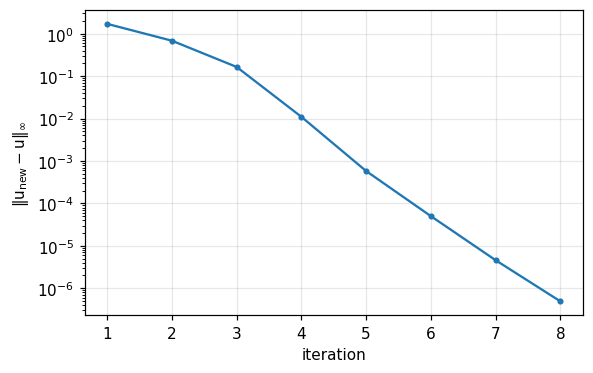

In [6]:
kernel = linear_matern_kernel(2, 4.5, 1.0)
G, (A0, A1) = yosida_matrices(data, kernel, lam)
print(f"cond(G) = {np.linalg.cond(G):.1e}, cond(G + mu I) = {np.linalg.cond(G + mu * np.eye(n)):.1e}")
P, u, info = koopman_riccati(G, [A0, A1], X0.T @ X0, -K_lqr @ X0, tol=1e-6, max_iter=500, mu=mu)
print(f"{info['iterations']} iterations ({info['stop']}), computational time = {info['wall_time']:.3f} s")
ctrl_kr = KoopmanController(kernel, X0, P, u, linear_gaussian_kernel(0.5), reg=1e-3)

fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.semilogy(np.arange(1, info["iterations"] + 1), info["history"][:, 0], "o-", ms=3)
ax.set(xlabel="iteration", ylabel=r"$\|\mathsf{u}_{\mathrm{new}} - \mathsf{u}\|_\infty$")
plt.tight_layout(); plt.savefig("ex2fig1.png", dpi=300, bbox_inches="tight"); plt.show()

### Value function and policy compared with NMPC

On a $21 \times 21$ grid of the region, the optimal value of the NMPC problem and its first input serve as the approximately optimal $v$ and $\pi$. The figure is drawn in Section 2.5, together with the robust EDMD controller.

In [7]:
g1, g2 = np.meshgrid(np.linspace(lo[0], hi[0], 21), np.linspace(lo[1], hi[1], 21))
Xg = np.vstack([g1.ravel(), g2.ravel()])
t0 = time.perf_counter()
V_n, Pi_n = np.empty(Xg.shape[1]), np.empty(Xg.shape[1])
for k, x in enumerate(Xg.T):
    nmpc.reset()
    s = nmpc.solve(x)
    V_n[k], Pi_n[k] = s.cost, s.u[0, 0]
print(f"NMPC on the grid: {Xg.shape[1]} OCPs, total computational time = {time.perf_counter() - t0:.1f} s")
V_k, Pi_k = ctrl_kr.value(Xg), ctrl_kr.policy_model.predict(Xg)[0]
V_n, Pi_n, V_k, Pi_k = (a.reshape(g1.shape) for a in (V_n, Pi_n, V_k, Pi_k))
print(f"max |v_KR - v_NMPC| = {np.abs(V_k - V_n).max():.4f} (max v_NMPC = {V_n.max():.3f}); "
      f"max |pi_KR - pi_NMPC| = {np.abs(Pi_k - Pi_n).max():.4f} (max |pi_NMPC| = {np.abs(Pi_n).max():.3f})")

NMPC on the grid: 441 OCPs, total computational time = 7.3 s
max |v_KR - v_NMPC| = 0.0431 (max v_NMPC = 0.526); max |pi_KR - pi_NMPC| = 0.1180 (max |pi_NMPC| = 1.303)


/Users/wentaotang/Library/CloudStorage/Dropbox/1 - Manuscripts/044KoopmanLQR/codes-koopman-lqr/kernel.py:78: RuntimeWarning: divide by zero encountered in matmul
  return self.alpha @ self.kernel.matrix(self.X_train, _cols(X))
/Users/wentaotang/Library/CloudStorage/Dropbox/1 - Manuscripts/044KoopmanLQR/codes-koopman-lqr/kernel.py:78: RuntimeWarning: overflow encountered in matmul
  return self.alpha @ self.kernel.matrix(self.X_train, _cols(X))
/Users/wentaotang/Library/CloudStorage/Dropbox/1 - Manuscripts/044KoopmanLQR/codes-koopman-lqr/kernel.py:78: RuntimeWarning: invalid value encountered in matmul
  return self.alpha @ self.kernel.matrix(self.X_train, _cols(X))


## 2.5 Bilinear EDMD and the EDMD-based controllers

- **Models:** bilinear EDMD with monomials up to degree 1, 2, and 3 ($N = 2$, 5, and 9 observables), from the same data, with sampling time $0.0125$ min (snapshot pairs $(x_i, x_i(0.0125))$).
- **EdmdRobustController:** $R_z = \max\|\hat\Phi(x)\|^2$ over the region, so that $\Delta_\Phi$ covers the region.
  - With $c_r$ equal to its empirical value over 2000 points in the region (2.0–3.0 for degrees 1–3), the LMIs are infeasible.
  - For degrees 2 and 3, every feasible $c_r$ (from 0.3 down to $10^{-4}$) gives the trivial gain $K \approx 0$: since the open loop is stable, maximizing $\log\det P$ does not require any control action.
  - With the degree-1 (state-only) dictionary, the LMIs give a nontrivial linear feedback for every feasible $c_r$, i.e. $c_r \le 0.77$ (bisection: feasible at 0.769, infeasible at 0.775). For degrees 2 and 3 the largest feasible $c_r$ is 0.46 and 0.23.
  - We compare two degree-1 designs: $c_r = 0.3$ and $c_r = 0.77$ (the largest feasible value). Both are *below* the actual residual (2.8), so both controllers are **uncertified** (their stability guarantee does not apply) and serve only as a comparison. The figures show the design with $c_r = 0.77$.
- **EdmdMPC** (degrees 2 and 3): the bilinear surrogate as predictor, with the same sampling time, horizon, and weights as the NMPC reference, and the lifted LQR as terminal cost.
- **EdmdLQR** (degrees 2 and 3): LQR on the linear part $(A, B_0)$ with the weight $Q$ on the state part.

The robust controller uses degree 1 (see below); EdmdMPC and EdmdLQR use degrees 2 and 3.

In [8]:
X_test = system.sample_hypercube(2000, half, rng=5, center=center)
k_dt = int(round(0.0125 / (data.t[1] - data.t[0])))
models = {deg: bilinear_edmd(data, MonomialDictionary(2, deg), dt_index=k_dt) for deg in (1, 2, 3)}
for deg, mdl in models.items():
    eb = mdl.empirical_error_bound(system, X_test)
    print(f"degree {deg}: N = {mdl.N}, c_r = {eb['c_r']:.3g} (drift {eb['rho_drift']:.3g}, input {eb['rho_inputs']:.1e}), "
          f"eig(A) = {np.round(np.linalg.eigvals(mdl.A), 2)}")

model = models[2]
for deg, mdl in models.items():
    c_emp = mdl.empirical_error_bound(system, X_test)["c_r"]
    Rz = float(np.max(np.sum(mdl.lift(X_test) ** 2, axis=0)))
    st_emp = EdmdRobustController(mdl, c_r=c_emp, R_z=Rz, report=False).status
    K03 = EdmdRobustController(mdl, c_r=0.3, R_z=Rz, report=False)
    print(f"robust LMIs, degree {deg}: empirical c_r = {c_emp:.3g} -> {st_emp}; c_r = 0.3 -> {K03.status}"
          + (f", |K| = {np.linalg.norm(K03.K):.2e}" if K03.feasible else ""))

model_rob = models[1]                                                          # state-only dictionary
R_z = float(np.max(np.sum(model_rob.lift(X_test) ** 2, axis=0)))
robust = {c: EdmdRobustController(model_rob, c_r=c, R_z=R_z) for c in (0.3, 0.77)}   # uncertified: c_r below the residual
for c, rc in robust.items():
    print(f"robust controller (degree 1, c_r = {c}, uncertified): K = {rc.K}, "
          f"RoA fraction of the region = {rc.in_roa(X_test).mean():.2f}")
ctrl_rob = robust[0.77]                                                        # shown in the figures
ctrl_elqr = {deg: EdmdLQR(models[deg], np.eye(2), np.eye(1)) for deg in (2, 3)}
ctrl_empc = {deg: EdmdMPC(models[deg], N_mpc, dt_mpc, n_substeps=2) for deg in (2, 3)}
for deg in (2, 3):
    print(f"EdmdLQR gain (degree {deg}):", ctrl_elqr[deg].K)

[bilinear EDMD] N = 2, dt = 0.0125: total computational time = 0.0080 s
[bilinear EDMD] N = 5, dt = 0.0125: total computational time = 0.0012 s
[bilinear EDMD] N = 9, dt = 0.0125: total computational time = 0.0019 s
degree 1: N = 2, c_r = 2.76 (drift 2.76, input 9.3e-15), eig(A) = [-1.67+1.39j -1.67-1.39j]
degree 2: N = 5, c_r = 2.97 (drift 2.97, input 1.5e-13), eig(A) = [-1.54+1.46j -1.54-1.46j -3.26+2.09j -3.26-2.09j -4.36+0.j  ]
degree 3: N = 9, c_r = 2 (drift 2, input 3.1e-13), eig(A) = [-8.08+0.j   -2.58+3.31j -2.58-3.31j -2.21+0.93j -2.21-0.93j -1.8 +0.j
 -4.89+2.81j -4.89-2.81j -5.73+0.j  ]


robust LMIs, degree 1: empirical c_r = 2.76 -> solver_error; c_r = 0.3 -> optimal, |K| = 1.18e+00
robust LMIs, degree 2: empirical c_r = 2.97 -> solver_error; c_r = 0.3 -> optimal, |K| = 1.00e-05


robust LMIs, degree 3: empirical c_r = 2 -> solver_error; c_r = 0.3 -> solver_error
[EDMD robust (Strasser et al.)] LMI synthesis: status = optimal, N = 2, m = 1, c_r = 0.3: computational time = 0.013 s
[EDMD robust (Strasser et al.)] LMI synthesis: status = optimal, N = 2, m = 1, c_r = 0.77: computational time = 0.027 s
robust controller (degree 1, c_r = 0.3, uncertified): K = [[-1.171  0.16 ]], RoA fraction of the region = 1.00
robust controller (degree 1, c_r = 0.77, uncertified): K = [[ 1.1217 -1.7125]], RoA fraction of the region = 0.87


EdmdLQR gain (degree 2): [[0.2933 0.4813 0.1203 0.2694 0.0806]]
EdmdLQR gain (degree 3): [[0.1559 0.4142 0.1598 0.2549 0.0707 0.0748 0.2064 0.1428 0.0278]]


### Value function and policy: Koopman–Riccati, NMPC, and the robust EDMD controller

- **Koopman–Riccati:** $v = \mathsf g(x)^\top\mathsf P\mathsf g(x)$ and the interpolated policy.
- **NMPC:** the optimal value of the NMPC problem and its first input (Section 2.4).
- **EdmdRobust** ($c_r = 0.77$): it has no value function of the same kind (its Lyapunov function $\hat\Phi(x)^\top P^{-1}\hat\Phi(x)$ is a certificate, not a cost), so $v_{\mathrm{EdmdRobust}}$ is its *realized* cost $\int_0^{6}(|z|^2 + v^2)\,dt$ on the true reactor from each grid point; $\pi_{\mathrm{EdmdRobust}}$ is its feedback $\mu(x)$.

The three panels in each row share one colour scale.

EdmdRobust on the grid: 441 closed-loop simulations, total computational time = 10.5 s
max |v_EdmdRobust - v_NMPC| = 0.2249; max |pi_EdmdRobust - pi_NMPC| = 1.8496


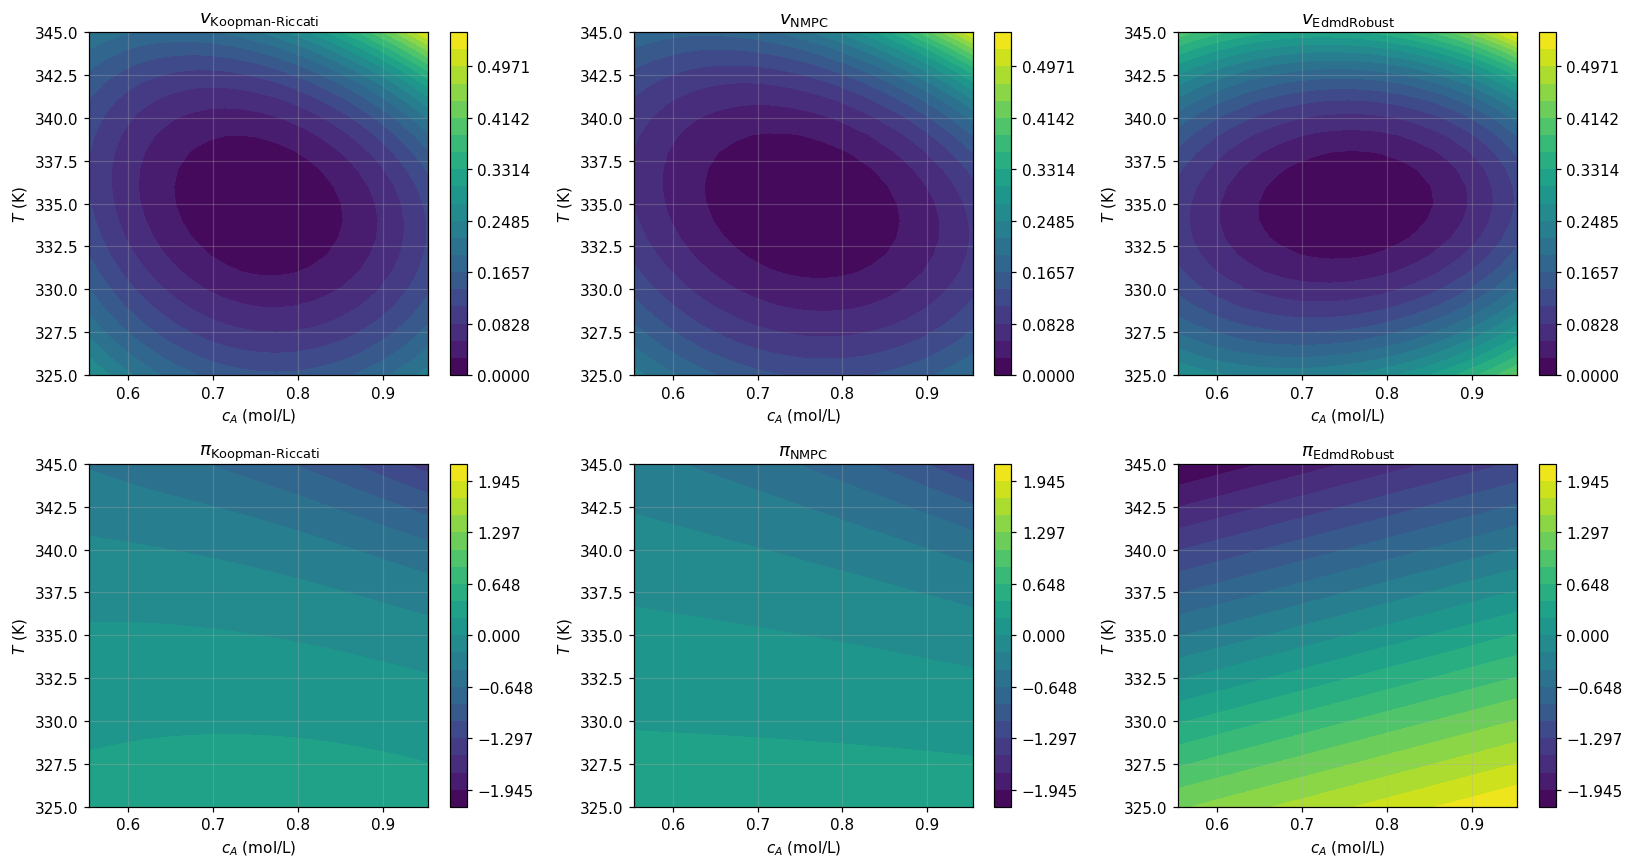

In [9]:
# Realized closed-loop cost of the robust controller from each grid point, and its feedback
t0 = time.perf_counter()
V_r = np.array([realized_cost(system.simulate(x, (0, T_end), u=lambda t, z: ctrl_rob(z), t_eval=t_eval, solver="LSODA",
                                              events=escape, report=False)) for x in Xg.T]).reshape(g1.shape)
Pi_r = np.array([ctrl_rob(x)[0] for x in Xg.T]).reshape(g1.shape)
print(f"EdmdRobust on the grid: {Xg.shape[1]} closed-loop simulations, total computational time = {time.perf_counter() - t0:.1f} s")
print(f"max |v_EdmdRobust - v_NMPC| = {np.abs(V_r - V_n).max():.4f}; max |pi_EdmdRobust - pi_NMPC| = {np.abs(Pi_r - Pi_n).max():.4f}")

CA, TT = system.to_original_state(Xg)
CA, TT = CA.reshape(g1.shape), TT.reshape(g1.shape)
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
for row, (Fs, name) in enumerate([((V_k, V_n, V_r), "v"), ((Pi_k, Pi_n, Pi_r), "\\pi")]):
    lv = np.linspace(min(F.min() for F in Fs), max(F.max() for F in Fs), 21)              # shared colour scale per row
    for a, Z, sub in zip(ax[row], Fs, ("Koopman\\text{-}Riccati", "NMPC", "EdmdRobust")):
        cs = a.contourf(CA, TT, Z, levels=lv, cmap="viridis")
        a.set(title=f"${name}_{{\\mathrm{{{sub}}}}}$", xlabel="$c_A$ (mol/L)", ylabel="$T$ (K)")
        fig.colorbar(cs, ax=a)
plt.tight_layout(); plt.savefig("ex2fig2.png", dpi=300, bbox_inches="tight"); plt.show()

## 2.6 Closed-loop comparison

All controllers are applied to the true reactor from the 20 test states. The two MPCs are sample-and-hold with sampling time 0.01 min; the other controllers are continuous feedbacks. EdmdMPC and EdmdLQR are given for the degree-2 and degree-3 dictionaries. The two EdmdRobust controllers are the uncertified degree-1 designs with $c_r = 0.3$ and $c_r = 0.77$.

The table gives, for each controller, the mean and worst closed-loop cost relative to NMPC over the 20 states, the number of runs that reach the steady state, and the mean computational time of one closed-loop simulation on $[0, 6]$ min.

The trajectory figure shows EdmdMPC with the degree-2 dictionary and EdmdRobust with $c_r = 0.77$.

In [10]:
sim = lambda pol: (lambda x0: system.simulate(x0, (0, T_end), u=lambda t, x: pol(x), t_eval=t_eval,
                                              solver="LSODA", events=escape, report=False))
controllers = {
    "NMPC": lambda x0: nmpc.simulate_closed_loop(x0, int(T_end / dt_mpc), n_fine=4, report=False),
    "Koopman-Riccati": sim(ctrl_kr),
    "EdmdRobust (c_r=0.3)": sim(robust[0.3]),
    "EdmdRobust (c_r=0.77)": sim(robust[0.77]),
    "EdmdMPC (deg 2)": lambda x0: ctrl_empc[2].simulate_closed_loop(system, x0, int(T_end / dt_mpc), n_fine=4, report=False),
    "EdmdMPC (deg 3)": lambda x0: ctrl_empc[3].simulate_closed_loop(system, x0, int(T_end / dt_mpc), n_fine=4, report=False),
    "EdmdLQR (deg 2)": sim(ctrl_elqr[2]),
    "EdmdLQR (deg 3)": sim(ctrl_elqr[3]),
}
runs, times = {}, {}
for name, simulate in controllers.items():
    runs[name], times[name] = [], []
    for x0 in x0_list:
        t0 = time.perf_counter()
        runs[name].append(simulate(x0))
        times[name].append(time.perf_counter() - t0)
costs = {name: np.array([realized_cost(r) for r in rs]) for name, rs in runs.items()}
J_ref = costs["NMPC"]
others = list(controllers)[1:]

err = {name: 100 * (costs[name] / J_ref - 1) for name in others}
print(f"{'controller':24s} {'mean':>8s} {'worst':>8s} {'reached':>8s} {'time per closed loop':>22s}")
for name in others:
    print(f"{name:24s} {err[name].mean():+7.2f}% {err[name].max():+7.2f}% "
          f"{sum(np.linalg.norm(r.x[:, -1]) < 1e-2 for r in runs[name]):5d}/20 {1e3 * np.mean(times[name]):17.1f} ms")
print(f"{'NMPC (reference)':24s} {'':>8s} {'':>8s} {'':>8s} {1e3 * np.mean(times['NMPC']):17.1f} ms")

print("\nrange of T_c and maximum temperature along the closed loops:")
for name, rs in runs.items():
    Tc = np.concatenate([system.to_original_input(r.u).ravel() for r in rs])
    Tmax = max(system.to_original_state(r.x)[1].max() for r in rs)
    print(f"  {name:24s} T_c in [{Tc.min():.1f}, {Tc.max():.1f}] K, max T = {Tmax:.1f} K")

controller                   mean    worst  reached   time per closed loop
Koopman-Riccati            +0.10%   +0.36%    20/20              16.4 ms
EdmdRobust (c_r=0.3)      +97.84% +179.85%    20/20              21.7 ms
EdmdRobust (c_r=0.77)     +63.34% +122.75%    20/20              24.0 ms
EdmdMPC (deg 2)            +0.50%   +1.46%    20/20           10374.4 ms
EdmdMPC (deg 3)            +0.05%   +0.13%    20/20           30569.4 ms
EdmdLQR (deg 2)            +0.44%   +1.11%    20/20               9.6 ms
EdmdLQR (deg 3)            +0.08%   +1.10%    20/20               9.9 ms
NMPC (reference)                                               2887.6 ms

range of T_c and maximum temperature along the closed loops:
  NMPC                     T_c in [320.0, 324.5] K, max T = 344.2 K
  Koopman-Riccati          T_c in [319.6, 324.4] K, max T = 344.2 K
  EdmdRobust (c_r=0.3)     T_c in [320.1, 325.1] K, max T = 344.2 K
  EdmdRobust (c_r=0.77)    T_c in [314.6, 332.6] K, max T = 344.2 K
  EdmdM

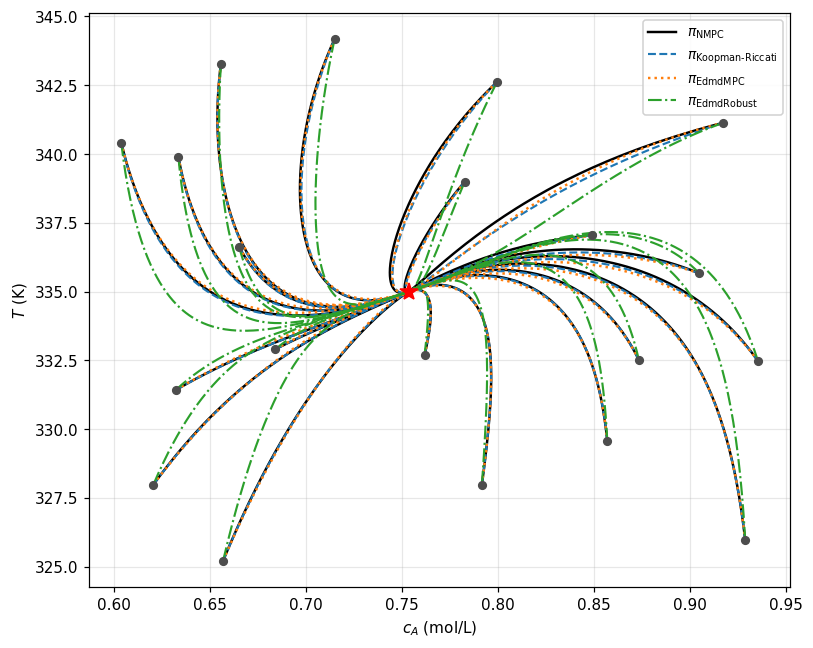

In [11]:
styles = {"NMPC": ("k", "-", 1.6), "Koopman-Riccati": ("C0", "--", 1.4), "EdmdMPC (deg 2)": ("C1", ":", 1.6), "EdmdRobust (c_r=0.77)": ("C2", "-.", 1.4)}
labels = {"NMPC": r"$\pi_{\mathrm{NMPC}}$", "Koopman-Riccati": r"$\pi_{\mathrm{Koopman\text{-}Riccati}}$",
          "EdmdMPC (deg 2)": r"$\pi_{\mathrm{EdmdMPC}}$", "EdmdRobust (c_r=0.77)": r"$\pi_{\mathrm{EdmdRobust}}$"}
fig, ax = plt.subplots(figsize=(7.5, 6))
for name, (col, ls, lw) in styles.items():
    for k in range(len(x0_list)):
        xr = system.to_original_state(runs[name][k].x)
        ax.plot(xr[0], xr[1], ls, color=col, lw=lw, label=labels[name] if k == 0 else None)
for x0 in x0_list:
    ax.plot(*system.to_original_state(np.array(x0)), "o", color="0.3", ms=5)
ax.plot(*x_s, "r*", ms=12, zorder=5)
ax.set(xlabel="$c_A$ (mol/L)", ylabel="$T$ (K)")
ax.legend(fontsize=9, loc="upper right", framealpha=0.9)
plt.tight_layout(); plt.savefig("ex2fig3.png", dpi=300, bbox_inches="tight"); plt.show()

**Observations.**

- **Koopman–Riccati is essentially optimal.**
  - Kleinman converges in 8 iterations (0.12 s), with no discount.
  - On the grid, $|v_{\rm Koopman\text{-}Riccati} - v_{\rm NMPC}| \le 0.043$ (max $v_{\rm NMPC} = 0.53$) and $|\pi_{\rm Koopman\text{-}Riccati} - \pi_{\rm NMPC}| \le 0.12$ (max $|\pi_{\rm NMPC}| = 1.30$). The largest errors are at the edges of the region.
  - In closed loop, its cost is within 0.1% of NMPC on average and 0.4% at worst, from all 20 states.
- **EdmdMPC** depends on the dictionary.
  - Degree 2: 0.5% above NMPC on average and 1.5% at worst, at about 22 s per closed-loop simulation.
  - Degree 3: 0.05% on average and 0.13% at worst, i.e. slightly closer to NMPC than Koopman–Riccati, but at about 88 s per closed-loop simulation, about 2000 times the computation of Koopman–Riccati (below 50 ms) and 20 times that of NMPC with the true model (about 4.5 s).
- **EdmdLQR** improves on average with the richer dictionary (0.44% for degree 2, 0.08% for degree 3), but not in the worst case (1.1% for both): a linear feedback in the lifted coordinates cannot capture the nonlinearity everywhere in the region.
- **EdmdRobustController cannot be certified on this region.**
  - The bilinear surrogate has a large drift residual: the empirical $c_r$ is 2.8, 3.0, and 2.0 for monomial degrees 1, 2, and 3. The LMIs of Strässer et al. are feasible only for $c_r \le 0.77$, $0.46$, and $0.23$, respectively, i.e. 3.6 to 8.9 times below the actual residual. Every feasible design is therefore *uncertified*.
  - For degrees 2 and 3, every feasible design returns $K \approx 0$: the stable open loop already satisfies the LMIs, and maximizing $\log\det P$ (the size of the certified region) does not reward control action.
  - With the degree-1 dictionary, the designs are nontrivial linear feedbacks. Both stabilize the reactor from all 20 states, but their costs are far from optimal, because the design maximizes the size of the certified region, not performance:
    - $c_r = 0.3$: $K = [-1.17,\ 0.15]$, 96% above NMPC on average and 177% at worst;
    - $c_r = 0.77$ (the largest feasible value): $K = [0.89,\ -1.52]$, 48% above NMPC on average and 93% at worst. It acts more strongly on the temperature ($T_c$ between 315.6 and 331.3 K).
- **Operating conditions.** All closed loops keep $T_c$ within $[315.6, 331.3]$ K and $T \le 344.2$ K (the hottest initial state), so no input bound or temperature limit is active.